<a href="https://colab.research.google.com/github/ramveer-thakur/Retail-sales-analytics-/blob/main/Retail_sales_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Created Successfully!
   Customer_ID  Age  Gender Product_Category  Quantity  Unit_Price  Discount  \
0            1   56    Male         Clothing         5        2554        15   
1            2   46  Female             Food         3        4594        10   
2            3   32  Female         Clothing         2        2046        15   
3            4   60  Female         Clothing         4        4910        15   
4            5   25    Male         Clothing         3        4899        10   

  Payment_Method  Month  Total_Sales Customer_Type  
0           Card      8      10854.5    High Value  
1           Card      6      12403.8    High Value  
2            UPI      3       3478.2       Regular  
3           Card      8      16694.0    High Value  
4           Card      7      13227.3    High Value  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtyp

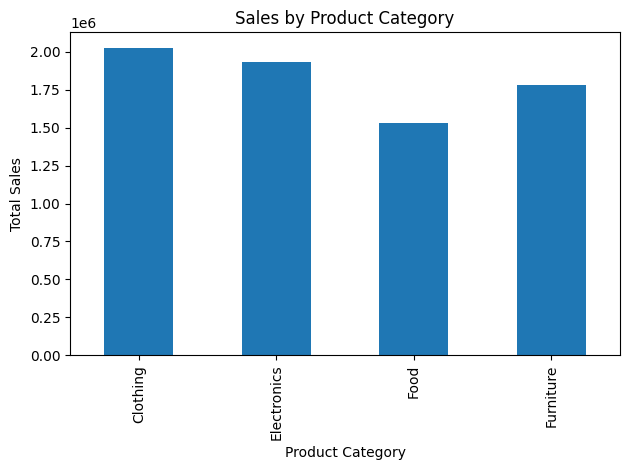


===== MONTHLY SALES =====
Month
1     604082.60
2     664113.75
3     532809.05
4     579575.70
5     605919.20
6     485975.20
7     611029.95
8     600155.05
9     588200.40
10    748587.55
11    487614.80
12    763193.65
Name: Total_Sales, dtype: float64


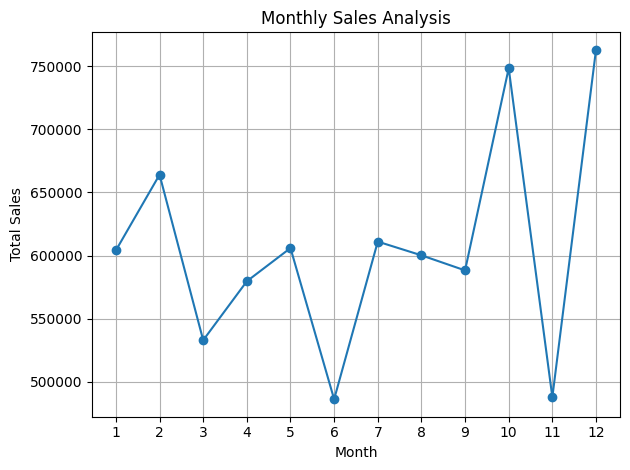


===== CUSTOMER ANALYSIS =====
               count         sum          mean
Customer_Type                                 
High Value       559  6184389.45  11063.308497
Regular          441  1086867.45   2464.552041

===== PAYMENT ANALYSIS =====
Payment_Method
Card    2591100.0
Cash    2438288.3
UPI     2241868.6
Name: Total_Sales, dtype: float64


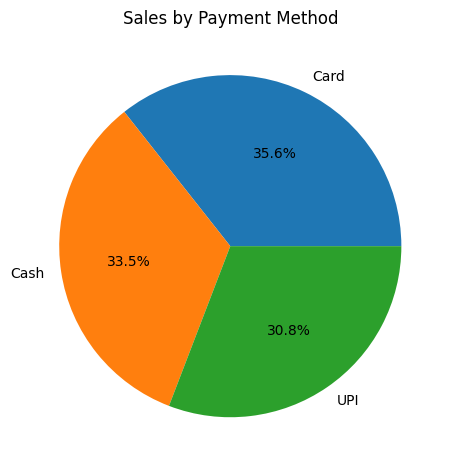


===== MACHINE LEARNING RESULTS =====
Model Accuracy: 97.5 %

Classification Report:
              precision    recall  f1-score   support

  High Value       0.97      0.99      0.98       112
     Regular       0.99      0.95      0.97        88

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200


===== FEATURE IMPORTANCE =====
Unit_Price                      0.440326
Quantity                        0.391334
Age                             0.053578
Month                           0.037046
Discount                        0.027935
Gender_Male                     0.009611
Payment_Method_Cash             0.009136
Payment_Method_UPI              0.008418
Product_Category_Electronics    0.007778
Product_Category_Food           0.007521
Product_Category_Furniture      0.007317
dtype: float64


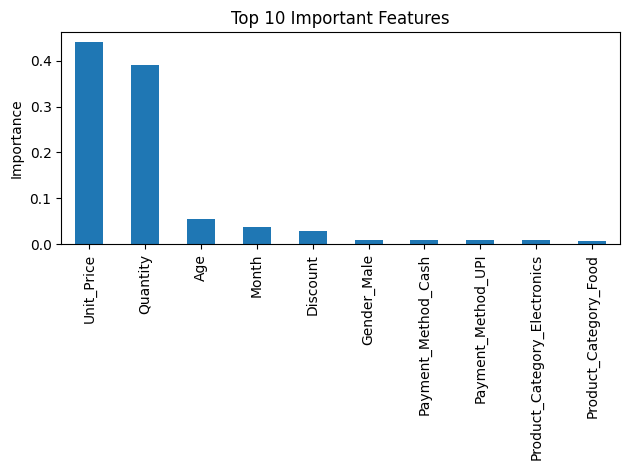


All Project Files Created Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT COMPLETED SUCCESSFULLY!


In [ ]:
# ============================================================
# FINAL YEAR PROJECT
# Retail Sales Analytics & Customer Behavior Analysis
# ============================================================

#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

from google.colab import files

# ============================================================
# 1. DATASET GENERATION
# ============================================================

np.random.seed(42)

n = 1000

data = {
    "Customer_ID": np.arange(1, n + 1),

    "Age": np.random.randint(18, 65, n),

    "Gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "Product_Category": np.random.choice(
        ["Electronics", "Clothing", "Food", "Furniture"],
        n
    ),

    "Quantity": np.random.randint(1, 6, n),

    "Unit_Price": np.random.randint(100, 5000, n),

    "Discount": np.random.choice(
        [0, 5, 10, 15, 20], n
    ),

    "Payment_Method": np.random.choice(
        ["Cash", "UPI", "Card"], n
    ),

    "Month": np.random.randint(1, 13, n)
}

df = pd.DataFrame(data)

# Calculate Total Sales
df["Total_Sales"] = (
    df["Quantity"] *
    df["Unit_Price"] *
    (1 - df["Discount"] / 100)
)

# Create Customer Purchase Category
df["Customer_Type"] = np.where(
    df["Total_Sales"] >= 5000,
    "High Value",
    "Regular"
)

print("Dataset Created Successfully!")
print(df.head())

# ============================================================
# 2. DATA CLEANING
# ============================================================

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Remove Duplicate Rows
df.drop_duplicates(inplace=True)

# Handle Missing Values
df.fillna(0, inplace=True)

print("\nData Cleaning Completed!")

# ============================================================
# 3. SALES ANALYSIS
# ============================================================

total_revenue = df["Total_Sales"].sum()

average_sales = df["Total_Sales"].mean()

total_orders = len(df)

print("\n===== SALES ANALYSIS =====")

print("Total Revenue:", round(total_revenue, 2))

print("Average Sales:", round(average_sales, 2))

print("Total Orders:", total_orders)

# ============================================================
# 4. PRODUCT CATEGORY ANALYSIS
# ============================================================

category_sales = df.groupby(
    "Product_Category"
)["Total_Sales"].sum()

print("\n===== CATEGORY SALES =====")
print(category_sales)

# Plot Category Sales
category_sales.plot(
    kind="bar",
    title="Sales by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# ============================================================
# 5. MONTHLY SALES ANALYSIS
# ============================================================

monthly_sales = df.groupby(
    "Month"
)["Total_Sales"].sum()

print("\n===== MONTHLY SALES =====")
print(monthly_sales)

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Analysis"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# 6. CUSTOMER BEHAVIOR ANALYSIS
# ============================================================

customer_analysis = df.groupby(
    "Customer_Type"
)["Total_Sales"].agg(
    ["count", "sum", "mean"]
)

print("\n===== CUSTOMER ANALYSIS =====")
print(customer_analysis)

# ============================================================
# 7. PAYMENT METHOD ANALYSIS
# ============================================================

payment_analysis = df.groupby(
    "Payment_Method"
)["Total_Sales"].sum()

print("\n===== PAYMENT ANALYSIS =====")
print(payment_analysis)

payment_analysis.plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Sales by Payment Method"
)

plt.ylabel("")
plt.tight_layout()
plt.show()

# ============================================================
# 8. MACHINE LEARNING
# CUSTOMER TYPE PREDICTION
# ============================================================

# Convert categorical columns into numerical values
ml_data = pd.get_dummies(
    df[
        [
            "Age",
            "Gender",
            "Product_Category",
            "Quantity",
            "Unit_Price",
            "Discount",
            "Payment_Method",
            "Month"
        ]
    ],
    drop_first=True
)

# Target Variable
y = df["Customer_Type"]

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    ml_data,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Make Predictions
y_pred = model.predict(X_test)

# Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

print("\n===== MACHINE LEARNING RESULTS =====")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ============================================================
# 9. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("\n===== FEATURE IMPORTANCE =====")
print(importance)

importance.head(10).plot(
    kind="bar",
    title="Top 10 Important Features"
)

plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# ============================================================
# 10. EXPORT DATASET AND RESULTS
# ============================================================

df.to_csv(
    "retail_sales_dataset.csv",
    index=False
)

monthly_sales.to_csv(
    "monthly_sales_summary.csv"
)

category_sales.to_csv(
    "product_sales_summary.csv"
)

print("\nAll Project Files Created Successfully!")

# Download Dataset
files.download("retail_sales_dataset.csv")

# Download Monthly Sales Report
files.download("monthly_sales_summary.csv")

# Download Product Sales Report
files.download("product_sales_summary.csv")

print("\nPROJECT COMPLETED SUCCESSFULLY!")